# A05 — Avaliação da clusterização dos dados integrados

## Pergunta

Os clusters que saem do processamento descrevem estados celulares, ou
descrevem a biblioteca, a profundidade e artefatos de preparo? E os problemas
que a análise da corrida antiga encontrou se repetem no ressequenciamento?

## Como se avalia, sem anotar

Nenhum cluster recebe nome de subtipo aqui. Cada agrupamento é examinado por
propriedades que não dependem de saber o que as células são:

| pergunta | medida |
| --- | --- |
| os clusters são de uma biblioteca ou de um paciente só? | composição normalizada pelo tamanho de cada biblioteca; número efetivo de pacientes |
| a integração misturou as bibliotecas? | vizinhos da mesma biblioteca antes e depois do Harmony |
| os clusters acompanham a profundidade? | variância do nº de UMIs explicada pelo cluster, dentro de cada biblioteca |
| o agrupamento é estável? | sementes diferentes; número de clusters por resolução |
| algum cluster é técnico? | QC por cluster; onde caem as células sinalizadas em A02 e A03 |
| o ressequenciamento mudou os clusters? | a mesma análise nas duas corridas, células pareadas |
| as citocinas aparecem nos clusters? | células positivas por cluster, com as definições conservadoras de C03 |

As três variantes de A04 são avaliadas com as mesmas medidas: **V1** é o
processamento original, **V2** corrige a PCA, **V3** corrige a PCA e usa o
universo completo de genes.

## Limite de inferência

São 7 pacientes e 14 bibliotecas. Os grupos MB e NP têm um paciente cada, e
41% das células vêm de um único paciente (PB21). Composições por grupo
clínico são descritas, não testadas. O único contraste testado é o pareado
dentro do paciente (estimulado × não estimulado, n = 7), e mesmo esse é
exploratório: cada biblioteca é um canal, de modo que estímulo e canal estão
confundidos.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import itertools
import time
import warnings
warnings.filterwarnings("ignore")

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from scipy import stats

from functions import config, fmt as F, io, pipeline as pl, plotting
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)
sc.settings.verbosity = 0

NB = "A05_avaliacao_clusterizacao"
log = IssueLog(NB)
LIBS = config.LIBRARIES
PATS = config.PATIENTS
INK = plotting.INK
VARS = pl.VARIANTS
VCOL = plotting.VARIANT_COLORS
VLAB = plotting.VARIANT_LABEL
BASE = "V3"                      # variante proposta como linha de base
LIB_LABEL = [f"{l.split('_')[0]}\n{l.split('_')[1]}" for l in LIBS]


def ckey(v):
    return f"leiden_{v}"


def clusters_of(v):
    return list(integ.obs[ckey(v)].cat.categories)

## Dados

In [2]:
integ = io.load_data("A04_processamento_integracao", "reseq_integrado", "h5ad")
obs = integ.obs
N = integ.n_obs
assert obs["cell_key"].is_unique

fa = io.load_data("A02_preprocessamento_adicional", "flags_adicionais")
fd = io.load_data("A03_doublets_recuperacao", "flags_doublets")
for t in (fa, fd):
    t.index = t["library_id"] + "|" + t["barcode"]
flags = pd.DataFrame(index=obs["cell_key"].to_numpy())
flags = flags.join(fa[["baixo_conteudo", "frac_intronica", "intronica_alta", "nao_T_azimuth", "azimuth_amplo", "frac_ribo"]])
flags = flags.join(fd[["com_B", "duplo_TB", "scrublet_calibrado"]])
assert not flags[["baixo_conteudo", "nao_T_azimuth", "com_B", "scrublet_calibrado"]].isna().any().any()
flags.index = obs.index

n_lib = obs["library_id"].astype(str).value_counts().reindex(LIBS)
n_pat = obs["patient"].astype(str).value_counts().reindex(PATS)
resumo = pd.DataFrame({v: {"clusters": len(clusters_of(v)),
                           "maior cluster": int(obs[ckey(v)].value_counts().max()),
                           "menor cluster": int(obs[ckey(v)].value_counts().min())} for v in VARS}).T
resumo.index = [VLAB[v] for v in VARS]
print(f"{F.n(N)} células × {F.n(integ.n_vars)} genes · {plotting.N_DESIGN}")
print(f"células por biblioteca: de {F.n(n_lib.min())} ({n_lib.idxmin()}) a {F.n(n_lib.max())} ({n_lib.idxmax()}); "
      f"{F.pct(n_pat.max() / N, 0)} das células vêm de {n_pat.idxmax()}")
resumo

35.064 células × 31.756 genes · 14 bibliotecas · 7 pacientes
células por biblioteca: de 70 (HNP44_NS) a 10.629 (PB21_ML); 41% das células vêm de PB21


,clusters,maior cluster,menor cluster
V1 fiel,14,5843,43
V2 PCA corrigida,10,8822,122
V3 + universo completo,13,8067,93


## 1. De onde vêm as células de cada cluster

Com bibliotecas tão desiguais, a composição bruta de um cluster repete o
tamanho das bibliotecas: PB21 tem 41% das células e aparece em primeiro em
quase tudo. Por isso a leitura é feita ao contrário: **que fração das células
de cada biblioteca cai em cada cluster**. Num cluster que representa um estado
celular comum, todas as bibliotecas colocam nele uma fração parecida das suas
células. Um cluster de uma biblioteca só aparece como uma coluna cheia e as
outras vazias.

O número efetivo de pacientes resume isso por cluster: vale 7 quando os sete
pacientes contribuem com a mesma proporção das suas células, e 1 quando o
cluster é de um paciente só.

In [3]:
share_lib, share_pat, comp = {}, {}, {}
linhas = []
for v in VARS:
    share_lib[v] = pl.share_within_group(obs, ckey(v), "library_id", LIBS)
    share_pat[v] = pl.share_within_group(obs, ckey(v), "patient", PATS)
    ct = pd.crosstab(obs[ckey(v)].astype(str), obs["library_id"].astype(str)).reindex(index=clusters_of(v), columns=LIBS)
    ctp = pd.crosstab(obs[ckey(v)].astype(str), obs["patient"].astype(str)).reindex(index=clusters_of(v), columns=PATS)
    comp[v] = ct
    ne_pat = pl.effective_number(share_pat[v])
    ne_lib = pl.effective_number(share_lib[v])
    for c in clusters_of(v):
        tot = int(ct.loc[c].sum())
        dom_l, dom_p = ct.loc[c].idxmax(), ctp.loc[c].idxmax()
        linhas.append({
            "variante": v, "cluster": c, "celulas": tot, "frac_do_total": tot / N,
            "bibliotecas_com_10_ou_mais": int((ct.loc[c] >= 10).sum()),
            "n_efetivo_bibliotecas": float(ne_lib[c]), "n_efetivo_pacientes": float(ne_pat[c]),
            "biblioteca_dominante": dom_l, "frac_do_cluster_na_dominante": float(ct.loc[c, dom_l] / tot),
            "enriquecimento_da_dominante": float((ct.loc[c, dom_l] / tot) / (n_lib[dom_l] / N)),
            "paciente_dominante": dom_p, "frac_do_cluster_no_paciente": float(ctp.loc[c, dom_p] / tot),
        })
    io.save_table(ct, NB, f"composicao_{v}", description=f"Células por cluster × biblioteca ({v})")
compos = pd.DataFrame(linhas)
compos["de_um_paciente"] = (compos["n_efetivo_pacientes"] < 2) & (compos["frac_do_cluster_no_paciente"] > 0.5)
io.save_table(compos, NB, "clusters_composicao", index=False,
              description="Composição de cada cluster: número efetivo de bibliotecas e pacientes, dominância")

sint = compos.groupby("variante").agg(
    clusters=("cluster", "size"),
    n_efetivo_pacientes_mediano=("n_efetivo_pacientes", "median"),
    n_efetivo_pacientes_minimo=("n_efetivo_pacientes", "min"),
    clusters_de_um_paciente=("de_um_paciente", "sum"),
    celulas_nesses_clusters=("celulas", lambda s: int(s[compos.loc[s.index, "de_um_paciente"]].sum())),
).reindex(VARS)
sint["frac_das_celulas"] = sint["celulas_nesses_clusters"] / N
io.save_table(sint, NB, "clusters_de_um_paciente", description="Clusters dominados por um paciente, por variante")
display(sint)
compos[compos["variante"] == BASE].drop(columns="variante").round(2)

,clusters,n_efetivo_pacientes_mediano,n_efetivo_pacientes_minimo,clusters_de_um_paciente,celulas_nesses_clusters,frac_das_celulas
variante,,,,,,
V1,14,5.379544,1.294024,2,3513,0.100188
V2,10,5.283525,1.502921,1,122,0.003479
V3,13,5.648154,1.612762,1,126,0.003593


,cluster,celulas,frac_do_total,bibliotecas_com_10_ou_mais,n_efetivo_bibliotecas,n_efetivo_pacientes,biblioteca_dominante,frac_do_cluster_na_dominante,enriquecimento_da_dominante,paciente_dominante,frac_do_cluster_no_paciente,de_um_paciente
24,0,8067,0.23,14,11.57,5.85,CTH94_NS,0.32,2.01,CTH94,0.34,False
25,1,7575,0.22,14,13.39,6.68,PB21_ML,0.38,1.25,PB21,0.50,False
26,2,4997,0.14,13,12.88,6.70,PB21_ML,0.35,1.16,PB21,0.48,False
27,3,4841,0.14,12,8.88,4.68,CTH97_ML,0.33,2.50,PB21,0.44,False
28,4,3751,0.11,14,12.02,6.09,CTH94_NS,0.25,1.57,PB21,0.36,False
29,5,2012,0.06,13,13.22,6.75,PB21_ML,0.36,1.18,PB21,0.47,False
30,6,1851,0.05,11,5.05,3.32,CTH97_ML,0.48,3.57,CTH97,0.49,False
31,7,1186,0.03,12,10.17,5.01,CTH94_NS,0.32,2.02,CTH94,0.35,False
32,8,282,0.01,9,6.51,3.89,CTH94_NS,0.27,1.67,CTH94,0.30,False
33,9,183,0.01,6,10.36,5.65,PB21_ML,0.44,1.44,PB21,0.52,False


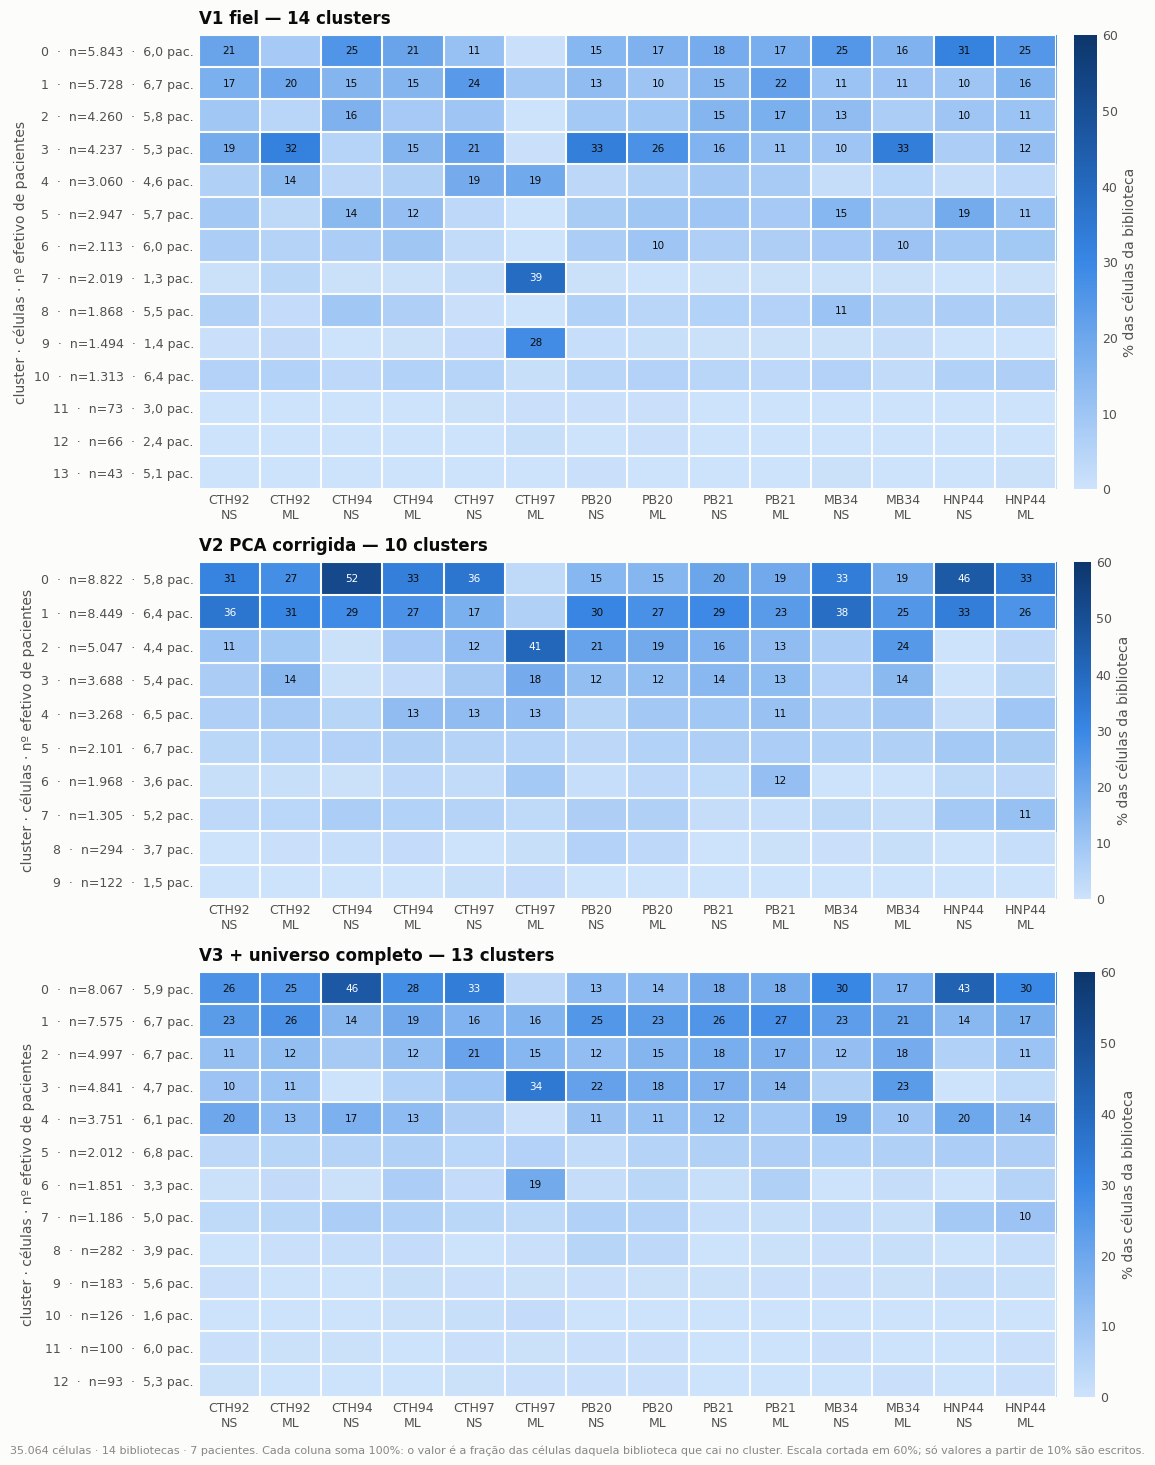

In [4]:
fig, axes = plt.subplots(len(VARS), 1, figsize=(11.5, 14.5),
                         gridspec_kw={"height_ratios": [len(clusters_of(v)) + 1.5 for v in VARS]})
dados_fig = []
for ax, v in zip(axes, VARS):
    m = share_lib[v].reindex(clusters_of(v)) * 100
    ne = pl.effective_number(share_pat[v]).reindex(clusters_of(v))
    tam = obs[ckey(v)].value_counts().reindex(clusters_of(v))
    m.index = [f"{c}  ·  n={F.n(tam[c])}  ·  {F.f(ne[c], 1)} pac." for c in m.index]
    m.columns = LIB_LABEL
    plotting.heatmap(ax, m, vmin=0, vmax=60, fmt=".0f", annotate_above=10,
                     cbar_label="% das células da biblioteca", xrotation=0)
    ax.set_title(f"{VLAB[v]} — {len(clusters_of(v))} clusters")
    ax.set_ylabel("cluster · células · nº efetivo de pacientes")
    dados_fig.append(share_lib[v].stack().rename("frac_da_biblioteca").reset_index()
                     .set_axis(["cluster", "library_id", "frac_da_biblioteca"], axis=1).assign(variante=v))
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Cada coluna soma 100%: o valor é a fração das células daquela "
                   "biblioteca que cai no cluster. Escala cortada em 60%; só valores a partir de 10% são escritos.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "composicao_por_biblioteca", description="Fração das células de cada biblioteca em cada cluster, por variante",
                 data=pd.concat(dados_fig), data_index=False)
plt.show()

In [5]:
b = compos[compos["variante"] == BASE].set_index("cluster")
um = compos[compos["de_um_paciente"]]
for v in VARS:
    d = um[um["variante"] == v]
    txt = "; ".join(f"cluster {r.cluster} ({F.n(r.celulas)} células, {F.pct(r.frac_do_cluster_no_paciente, 0)} de {r.paciente_dominante})"
                    for r in d.itertuples()) or "nenhum"
    print(f"{v}: clusters de um paciente só → {txt}")
print(f"{BASE}: número efetivo de pacientes por cluster de {F.f(b['n_efetivo_pacientes'].min(), 1)} a "
      f"{F.f(b['n_efetivo_pacientes'].max(), 1)} (mediana {F.f(b['n_efetivo_pacientes'].median(), 1)}, máximo possível 7)")

V1: clusters de um paciente só → cluster 7 (2.019 células, 92% de CTH97); cluster 9 (1.494 células, 91% de CTH97)
V2: clusters de um paciente só → cluster 9 (122 células, 86% de CTH97)
V3: clusters de um paciente só → cluster 10 (126 células, 85% de CTH97)
V3: número efetivo de pacientes por cluster de 1,6 a 6,8 (mediana 5,6, máximo possível 7)


### Onde cada biblioteca cai no UMAP (V3)

Um painel por biblioteca, com as células dela em destaque sobre todas as
outras em cinza. Bibliotecas integradas ocupam as mesmas regiões; uma
biblioteca que ocupa uma região só sua indica um efeito que a integração não
removeu — técnico ou biológico.

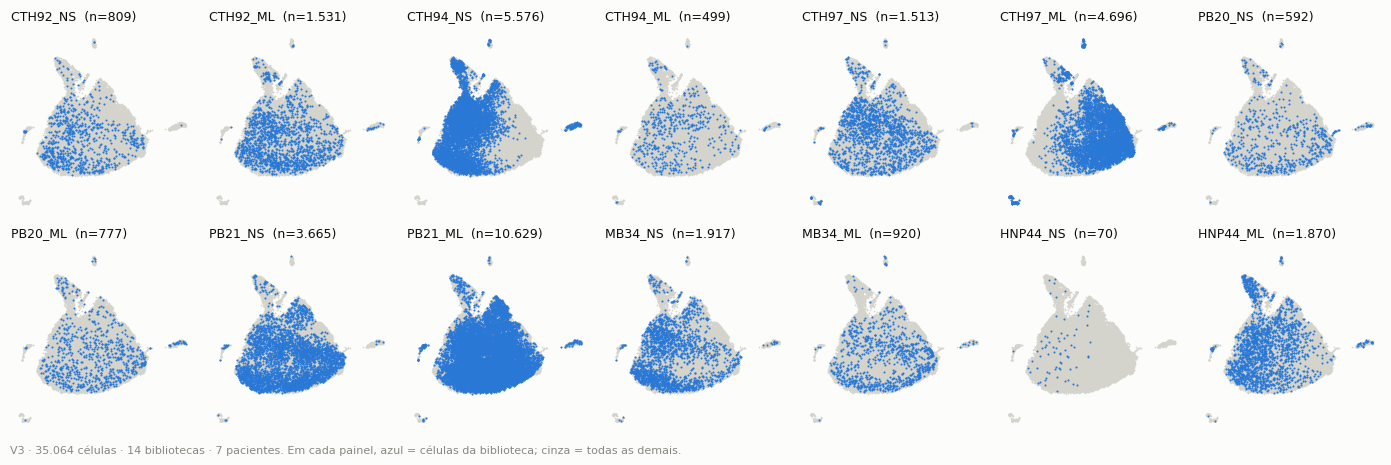

In [6]:
um_base = integ.obsm[f"X_umap_{BASE}"]
fig = plotting.umap_highlight_grid(um_base, obs["library_id"].astype(str).to_numpy(), order=LIBS, ncols=7,
                                   panel=2.0, s=1.4)
plotting.note(fig, f"{BASE} · {F.n(N)} células · {plotting.N_DESIGN}. Em cada painel, azul = células da biblioteca; "
                   "cinza = todas as demais.", y=0.0)
plotting.savefig(fig, NB, "umap_por_biblioteca", description="UMAP da V3 com cada biblioteca em destaque",
                 data=n_lib.rename("celulas").rename_axis("library_id").reset_index(), data_index=False)
plt.show()

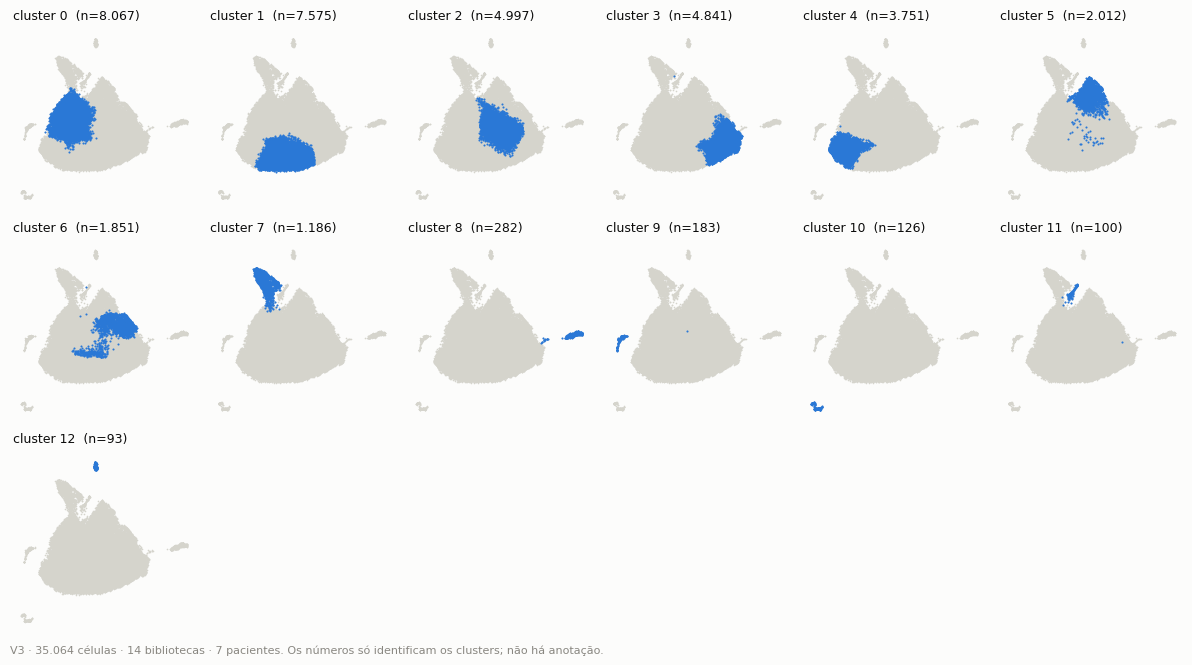

In [7]:
fig = plotting.umap_highlight_grid(um_base, obs[ckey(BASE)].astype(str).to_numpy(), order=clusters_of(BASE),
                                   ncols=6, panel=2.0, s=1.4,
                                   title_fmt=lambda g, n: f"cluster {g}  (n={F.n(n)})")
plotting.note(fig, f"{BASE} · {F.n(N)} células · {plotting.N_DESIGN}. Os números só identificam os clusters; não há anotação.",
              y=0.0)
plotting.savefig(fig, NB, "umap_por_cluster", description="UMAP da V3 com cada cluster em destaque",
                 data=obs[ckey(BASE)].value_counts().reindex(clusters_of(BASE)).rename("celulas")
                        .rename_axis("cluster").reset_index(), data_index=False)
plt.show()

## 2. A integração misturou as bibliotecas?

Para cada célula, que fração dos vizinhos no grafo é da mesma biblioteca.
Sob mistura perfeita essa fração é igual à parcela da biblioteca no conjunto
(uma biblioteca com 2% das células teria 2% de vizinhos próprios). Compara-se
o grafo construído sobre a PCA, antes da correção, com o grafo usado no
agrupamento, depois do Harmony.

Mistura total não é a meta: bibliotecas com composições diferentes devem
continuar diferentes. A medida serve para ver se sobra separação por
biblioteca que a correção não tocou — e, no outro sentido, se a correção por
biblioteca apagou a diferença entre estimulado e não estimulado, que neste
desenho são duas bibliotecas do mesmo paciente.

In [8]:
lib_arr = obs["library_id"].astype(str).to_numpy()
pat_arr = obs["patient"].astype(str).to_numpy()
mix, sep, linhas = {}, {}, []
for v in VARS:
    tmp = sc.AnnData(obs=obs[[]].copy())
    tmp.obsm["X_pca"] = integ.obsm[f"X_pca_{v}"]
    sc.pp.neighbors(tmp, use_rep="X_pca", n_pcs=config.N_DIMS_NEIGHBORS)
    grafos = {"antes": tmp.obsp["connectivities"], "depois": integ.obsp[f"connectivities_{v}"]}
    for quando, G in grafos.items():
        k = pl.knn_library_mixing(G, lib_arr)
        k["library_id"] = lib_arr
        por_lib = k.groupby("library_id")["frac_vizinhos_mesma_biblioteca"].mean().reindex(LIBS)
        mix[(v, quando)] = por_lib
        s = pl.within_patient_separation(G, lib_arr, pat_arr).reindex(LIBS)
        sep[(v, quando)] = s["separacao"]
        kp = pl.knn_library_mixing(G, pat_arr)
        linhas.append({"variante": v, "grafo": quando,
                       "vizinhos_mesma_biblioteca_mediana_bibliotecas": float(por_lib.median()),
                       "ilisi_bibliotecas_mediano": float(k["ilisi"].median()),
                       "ilisi_pacientes_mediano": float(kp["ilisi"].median()),
                       "separacao_NS_ML_mediana": float(s["separacao"].median())})
esperado = n_lib / N
mistura = pd.DataFrame(linhas).set_index(["variante", "grafo"])
mistura["ilisi_bibliotecas_esperado"] = pl.expected_ilisi(lib_arr)
mistura["ilisi_pacientes_esperado"] = pl.expected_ilisi(pat_arr)
io.save_table(mistura, NB, "mistura_resumo", description="Mistura de bibliotecas e pacientes na vizinhança, antes e depois do Harmony")
mix_tab = pd.DataFrame(mix)
mix_tab.columns = [f"{v}_{q}" for v, q in mix_tab.columns]
mix_tab["esperado_sob_mistura"] = esperado
io.save_table(mix_tab, NB, "mistura_por_biblioteca", description="Fração de vizinhos da mesma biblioteca, por biblioteca")
sep_tab = pd.DataFrame(sep)
sep_tab.columns = [f"{v}_{q}" for v, q in sep_tab.columns]
io.save_table(sep_tab, NB, "separacao_estimulo_por_biblioteca",
              description="Separação entre as duas bibliotecas do mesmo paciente (0 = misturadas, 1 = separadas)")
mistura.round(3)

vizinhos_mesma_biblioteca_mediana_bibliotecas  ilisi_bibliotecas_mediano  ilisi_pacientes_mediano  separacao_NS_ML_mediana  ilisi_bibliotecas_esperado  ilisi_pacientes_esperado
variante grafo                                                                                                                                                                                   
V1       antes                                           0.323                      1.967                    1.475                    0.335                       6.335                     4.113
         depois                                          0.169                      3.178                    2.380                    0.247                       6.335                     4.113
V2       antes                                           0.506                      1.306                    1.246                    0.600                       6.335                     4.113
         depois                                          0.107                      3.546                    2.783                    0.217                       6.335                     4.113
V3       antes                                           0.500                      1.316                    1.256                    0.607                       6.335                     4.113
         depois                                          0.098                      3.630                    2.843                    0.220                       6.335                     4.113

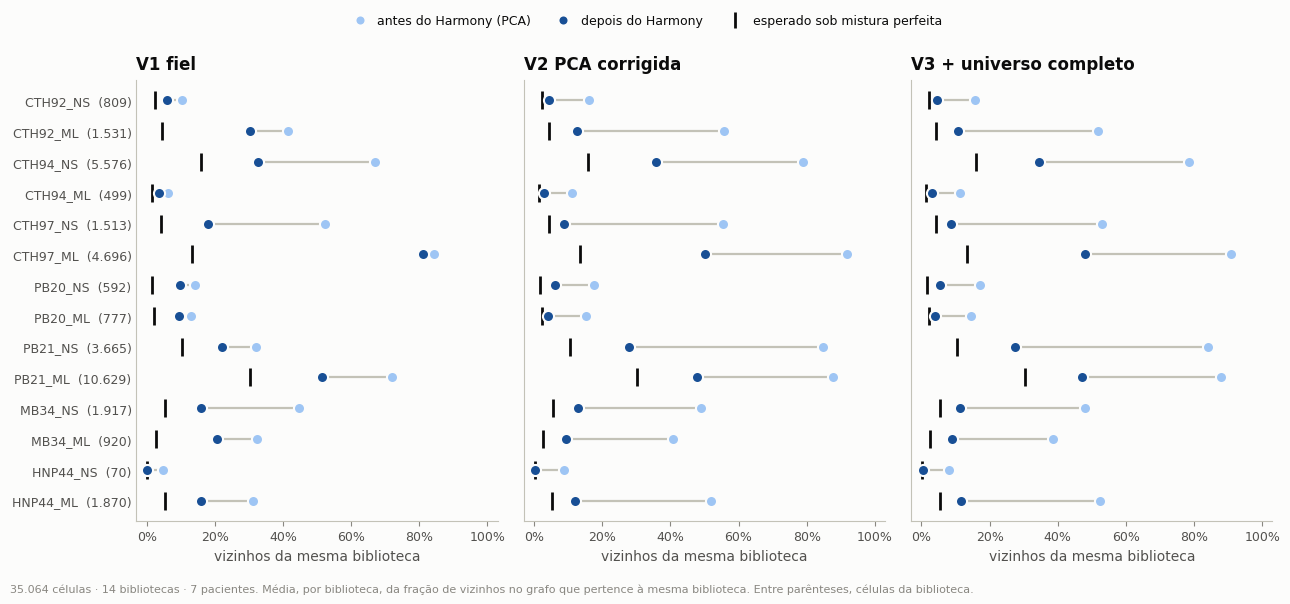

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 5.6), sharey=True)
y = np.arange(len(LIBS))[::-1]
for ax, v in zip(axes, VARS):
    antes, depois = mix[(v, "antes")], mix[(v, "depois")]
    for yi, l in zip(y, LIBS):
        ax.plot([antes[l], depois[l]], [yi, yi], color=INK["axis"], lw=1.6, zorder=1, solid_capstyle="round")
        ax.plot(esperado[l], yi, marker="|", ms=13, mew=2, color=INK["primary"], zorder=2, ls="")
        ax.plot(antes[l], yi, "o", ms=8, mfc=plotting.OLD_NEW_COLORS["antiga"], mec=INK["surface"], mew=1.5, zorder=3)
        ax.plot(depois[l], yi, "o", ms=8, mfc=plotting.OLD_NEW_COLORS["nova"], mec=INK["surface"], mew=1.5, zorder=4)
    ax.set_xlim(-0.03, 1.03)
    plotting.percent(ax, "x")
    ax.set_title(VLAB[v])
    ax.set_xlabel("vizinhos da mesma biblioteca")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
axes[0].set_yticks(y)
axes[0].set_yticklabels([f"{l}  ({F.n(n_lib[l])})" for l in LIBS])
handles = plotting.old_new_handles("antes do Harmony (PCA)", "depois do Harmony") + [
    mpl.lines.Line2D([], [], marker="|", ls="", ms=11, mew=2, color=INK["primary"], label="esperado sob mistura perfeita")]
fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.03))
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Média, por biblioteca, da fração de vizinhos no grafo que pertence "
                   "à mesma biblioteca. Entre parênteses, células da biblioteca.", y=0.0)
fig.tight_layout(rect=(0, 0.01, 1, 0.97))
plotting.savefig(fig, NB, "mistura_de_bibliotecas", description="Vizinhos da mesma biblioteca antes e depois do Harmony, por variante",
                 data=mix_tab.rename_axis("library_id").reset_index(), data_index=False)
plt.show()

In [10]:
mb = mistura.loc[BASE]
print(f"{BASE} — vizinhos da mesma biblioteca (mediana das bibliotecas): "
      f"{F.pct(mb.loc['antes', 'vizinhos_mesma_biblioteca_mediana_bibliotecas'], 0)} antes → "
      f"{F.pct(mb.loc['depois', 'vizinhos_mesma_biblioteca_mediana_bibliotecas'], 0)} depois do Harmony "
      f"(esperado sob mistura perfeita: mediana {F.pct(esperado.median(), 0)})")
print(f"{BASE} — separação entre estimulado e não estimulado do mesmo paciente (0 a 1): "
      f"{F.f(mb.loc['antes', 'separacao_NS_ML_mediana'], 2)} antes → {F.f(mb.loc['depois', 'separacao_NS_ML_mediana'], 2)} depois")
for v in VARS:
    r = mistura.loc[v]
    print(f"{v}: iLISI de pacientes {F.f(r.loc['antes', 'ilisi_pacientes_mediano'], 2)} → "
          f"{F.f(r.loc['depois', 'ilisi_pacientes_mediano'], 2)} (esperado {F.f(r.loc['depois', 'ilisi_pacientes_esperado'], 2)}); "
          f"separação NS×ML {F.f(r.loc['antes', 'separacao_NS_ML_mediana'], 2)} → {F.f(r.loc['depois', 'separacao_NS_ML_mediana'], 2)}")
resid = (mix[(BASE, "depois")] / esperado).sort_values(ascending=False)
print(f"{BASE}, depois do Harmony — bibliotecas com mais vizinhos próprios em relação ao esperado: "
      + "; ".join(f"{l} {F.f(x, 1)}×" for l, x in resid.head(4).items()))

V3 — vizinhos da mesma biblioteca (mediana das bibliotecas): 50% antes → 10% depois do Harmony (esperado sob mistura perfeita: mediana 4%)
V3 — separação entre estimulado e não estimulado do mesmo paciente (0 a 1): 0,61 antes → 0,22 depois
V1: iLISI de pacientes 1,47 → 2,38 (esperado 4,11); separação NS×ML 0,34 → 0,25
V2: iLISI de pacientes 1,25 → 2,78 (esperado 4,11); separação NS×ML 0,60 → 0,22
V3: iLISI de pacientes 1,26 → 2,84 (esperado 4,11); separação NS×ML 0,61 → 0,22
V3, depois do Harmony — bibliotecas com mais vizinhos próprios em relação ao esperado: CTH97_ML 3,6×; MB34_ML 3,4×; PB20_NS 3,3×; PB21_NS 2,6×


## 3. Os clusters acompanham a profundidade?

A auditoria anterior mostrou que, no processamento original, os eixos em que
os clusters são construídos acompanhavam o número de UMIs por célula. A medida
usada aqui é direta: **que fração da variância do log do número de UMIs é
explicada pelo cluster**, calculada dentro de cada biblioteca (para que a
diferença de profundidade entre bibliotecas não entre na conta). Células de
estados diferentes têm quantidades diferentes de RNA, então algum valor é
esperado; o que interessa é a comparação entre variantes e com a corrida
antiga processada do mesmo modo.

In [11]:
log_umis = np.log10(obs["total_counts"].to_numpy())
ant = io.load_data("A04_processamento_integracao", "antiga_variantes")
eta = {}
for v in VARS:
    eta[f"nova · {v}"] = pl.eta_squared_within(log_umis, obs[ckey(v)], lib_arr)
    eta[f"antiga · {v}"] = pl.eta_squared_within(np.log10(ant["total_counts"]), ant[ckey(v)], ant["library_id"])
eta_tab = pd.DataFrame(eta).reindex(LIBS)
eta_glob = pd.Series({**{f"nova · {v}": pl.eta_squared(log_umis, obs[ckey(v)]) for v in VARS},
                      **{f"antiga · {v}": pl.eta_squared(np.log10(ant["total_counts"]), ant[ckey(v)]) for v in VARS}})
prof = pd.DataFrame({"mediana entre bibliotecas": eta_tab.median(), "mínimo": eta_tab.min(), "máximo": eta_tab.max(),
                     "bibliotecas avaliadas (≥ 200 células)": eta_tab.notna().sum(),
                     "todas as células juntas": eta_glob})
io.save_table(eta_tab, NB, "profundidade_eta2_por_biblioteca",
              description="Fração da variância de log10(UMIs) explicada pelo cluster, dentro de cada biblioteca")
io.save_table(prof, NB, "profundidade_eta2", description="Variância de log10(UMIs) explicada pelo cluster: resumo por variante e corrida")
prof.round(3)

,mediana entre bibliotecas,mínimo,máximo,bibliotecas avaliadas (≥ 200 células),todas as células juntas
antiga · V1,0.572,0.527,0.689,13,0.626
antiga · V2,0.231,0.152,0.346,13,0.201
antiga · V3,0.210,0.136,0.341,13,0.198
nova · V1,0.568,0.492,0.676,13,0.664
nova · V2,0.189,0.089,0.334,13,0.220
nova · V3,0.219,0.143,0.375,13,0.213


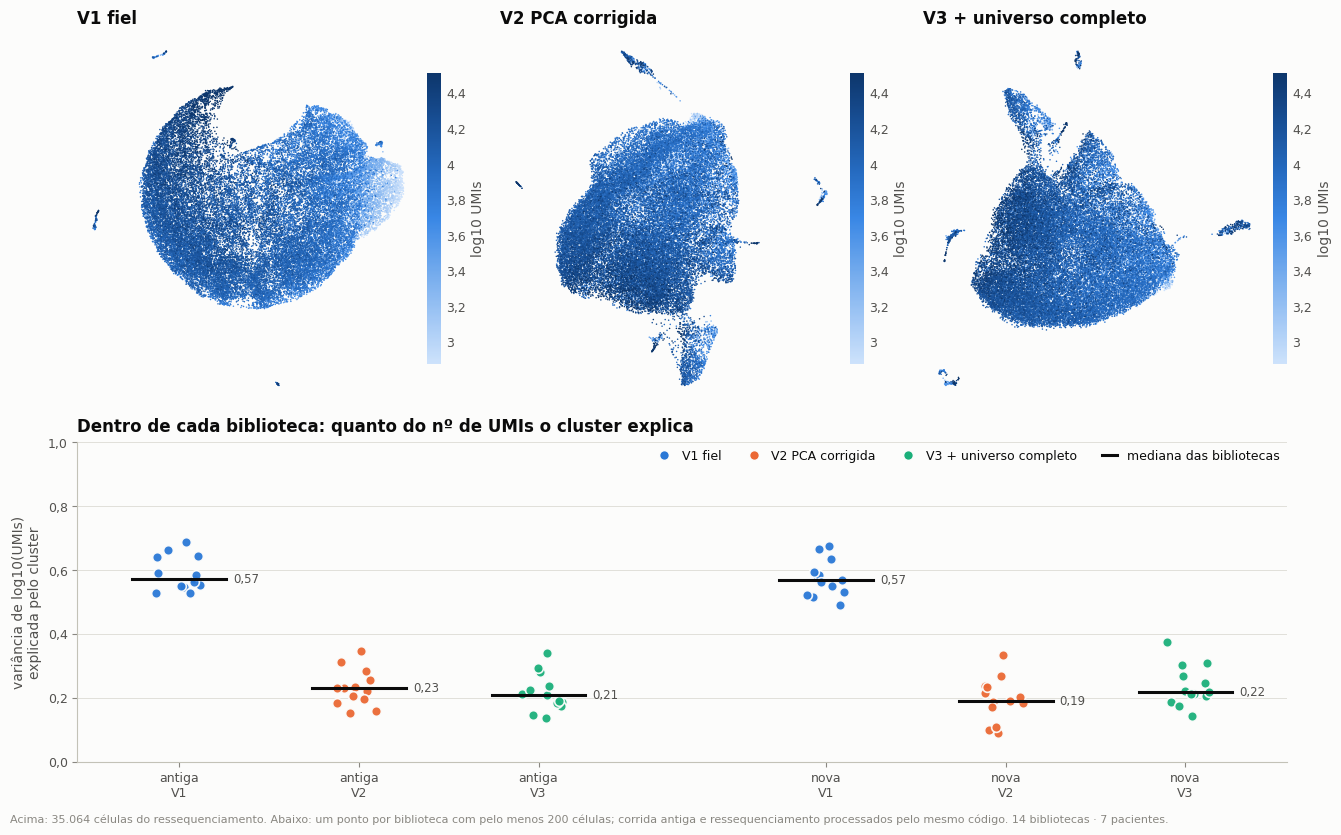

In [12]:
fig = plt.figure(figsize=(13.5, 8.2))
gs = fig.add_gridspec(2, 3, height_ratios=[1.15, 1])
for i, v in enumerate(VARS):
    ax = fig.add_subplot(gs[0, i])
    plotting.umap_continuous(ax, integ.obsm[f"X_umap_{v}"], log_umis, label="log10 UMIs",
                             vmin=np.quantile(log_umis, 0.01), vmax=np.quantile(log_umis, 0.99))
    ax.set_title(f"{VLAB[v]}")
ax = fig.add_subplot(gs[1, :])
ordem_col = [f"antiga · {v}" for v in VARS] + [f"nova · {v}" for v in VARS]
rng = np.random.default_rng(0)
for j, col in enumerate(ordem_col):
    vals = eta_tab[col].dropna()
    v = col.split(" · ")[1]
    cor = VCOL[v]
    xj = j + (0.6 if j >= 3 else 0)
    ax.plot(xj + rng.uniform(-0.13, 0.13, len(vals)), vals, "o", ms=7, mfc=cor, mec=INK["surface"], mew=1.2,
            alpha=0.95, zorder=3)
    ax.plot([xj - 0.26, xj + 0.26], [vals.median()] * 2, color=INK["primary"], lw=2.2, zorder=4)
    ax.annotate(F.f(vals.median(), 2), (xj + 0.3, vals.median()), va="center", fontsize=8.5, color=INK["secondary"])
ax.set_xticks([j + (0.6 if j >= 3 else 0) for j in range(6)])
ax.set_xticklabels([c.replace(" · ", "\n") for c in ordem_col])
ax.set_ylim(0, 1)
plotting.decimals(ax, "y", 1)
ax.set_ylabel("variância de log10(UMIs)\nexplicada pelo cluster")
ax.set_title("Dentro de cada biblioteca: quanto do nº de UMIs o cluster explica")
ax.grid(axis="x", visible=False)
ax.legend(handles=[mpl.lines.Line2D([], [], marker="o", ls="", ms=7, mfc=VCOL[v], mec=INK["surface"], label=VLAB[v])
                   for v in VARS] + [mpl.lines.Line2D([], [], color=INK["primary"], lw=2.2, label="mediana das bibliotecas")],
          loc="upper right", ncol=4)
plotting.note(fig, f"Acima: {F.n(N)} células do ressequenciamento. Abaixo: um ponto por biblioteca com pelo menos 200 células; "
                   f"corrida antiga e ressequenciamento processados pelo mesmo código. {plotting.N_DESIGN}.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "profundidade_e_clusters", description="Número de UMIs no UMAP e variância explicada pelo cluster",
                 data=eta_tab.rename_axis("library_id").reset_index(), data_index=False)
plt.show()

In [13]:
med = prof["mediana entre bibliotecas"]
print("variância de log10(UMIs) explicada pelo cluster, mediana entre bibliotecas:")
for v in VARS:
    print(f"  {v}: corrida antiga {F.f(med[f'antiga · {v}'], 2)} → ressequenciamento {F.f(med[f'nova · {v}'], 2)}")

variância de log10(UMIs) explicada pelo cluster, mediana entre bibliotecas:
  V1: corrida antiga 0,57 → ressequenciamento 0,57
  V2: corrida antiga 0,23 → ressequenciamento 0,19
  V3: corrida antiga 0,21 → ressequenciamento 0,22


## 4. O agrupamento é estável?

Duas verificações sobre o grafo de cada variante. Primeiro, a semente: o
Leiden é estocástico, e uma partição que muda muito de uma semente para outra
não sustenta uma anotação. Segundo, a resolução: o número de clusters cresce
com ela, e um intervalo em que ele fica parado indicaria uma escala natural.
O valor do original, 0,5, é um deles.

In [14]:
RES = [round(r, 1) for r in np.arange(0.1, 1.01, 0.1)]
SEEDS = (0, 1, 2, 3)
t0 = time.time()
sweep, linhas, n_res, jac = {}, [], {}, {}
for v in VARS:
    sw = pl.leiden_sweep(integ, RES, seeds=(0,), obsp=f"connectivities_{v}")
    sd = pl.leiden_sweep(integ, [config.LEIDEN_RESOLUTION], seeds=SEEDS[1:], obsp=f"connectivities_{v}")
    sweep[v] = sw.join(sd)
    base_col = f"leiden_r{config.LEIDEN_RESOLUTION:g}_s0"
    igual = pl.clustering_agreement(sw[base_col], obs[ckey(v)])["ARI"]
    cols = [base_col] + list(sd.columns)
    aris = [pl.clustering_agreement(sweep[v][a], sweep[v][b])["ARI"] for a, b in itertools.combinations(cols, 2)]
    ks = [sweep[v][c].nunique() for c in cols]
    jac[v] = pl.cluster_stability(obs[ckey(v)], [sweep[v][c] for c in sd.columns])
    tam_v = obs[ckey(v)].value_counts()
    n_res[v] = pd.Series({r: sw[f"leiden_r{r:g}_s0"].nunique() for r in RES})
    viz = [pl.clustering_agreement(sw[f"leiden_r{a:g}_s0"], sw[f"leiden_r{b:g}_s0"])["ARI"] for a, b in zip(RES[:-1], RES[1:])]
    linhas.append({"variante": v, "ARI com o agrupamento gravado em A04": float(igual),
                   "ARI entre sementes (média)": float(np.mean(aris)), "ARI entre sementes (mínimo)": float(np.min(aris)),
                   "clusters por semente": " / ".join(str(k) for k in ks),
                   "clusters de 0,1 a 1,0": f"{n_res[v].iloc[0]} → {n_res[v].iloc[-1]}",
                   "maior intervalo de resolução sem mudar o nº de clusters":
                       round(0.1 * max(len(list(g)) for _, g in itertools.groupby(n_res[v].to_numpy())) - 0.1, 1),
                   "ARI entre resoluções vizinhas (mínimo)": float(np.min(viz)),
                   "clusters estáveis (Jaccard ≥ 0,75)": int((jac[v] >= 0.75).sum()),
                   "clusters instáveis (Jaccard < 0,5)": int((jac[v] < 0.5).sum()),
                   "células em clusters instáveis": float(tam_v.reindex(jac[v].index[jac[v] < 0.5]).sum() / N)})
estab = pd.DataFrame(linhas).set_index("variante")
n_res_tab = pd.DataFrame(n_res).rename_axis("resolução")
io.save_table(estab, NB, "estabilidade", description="Estabilidade do Leiden: sementes e resolução, por variante")
io.save_table(n_res_tab, NB, "clusters_por_resolucao", description="Número de clusters por resolução do Leiden")
jac_tab = pd.concat({v: jac[v] for v in VARS}, axis=1)
io.save_table(jac_tab, NB, "estabilidade_por_cluster",
              description="Jaccard médio de cada cluster com o melhor par em outras sementes do Leiden (resolução 0,5)")
print(f"{BASE}, Jaccard por cluster entre sementes: " + "; ".join(f"{c} {F.f(x, 2)}" for c, x in jac[BASE].items()))
print(f"{len(VARS) * (len(RES) + len(SEEDS) - 1)} execuções do Leiden em {time.time() - t0:.0f} s")
estab

V3, Jaccard por cluster entre sementes: 0 0,67; 1 0,53; 2 0,41; 3 0,71; 4 0,53; 5 0,93; 6 0,67; 7 0,95; 8 0,98; 9 1,00; 10 1,00; 11 0,67; 12 1,00
39 execuções do Leiden em 1702 s


,ARI com o agrupamento gravado em A04,ARI entre sementes (média),ARI entre sementes (mínimo),clusters por semente,"clusters de 0,1 a 1,0",maior intervalo de resolução sem mudar o nº de clusters,ARI entre resoluções vizinhas (mínimo),"clusters estáveis (Jaccard ≥ 0,75)","clusters instáveis (Jaccard < 0,5)",células em clusters instáveis
variante,,,,,,,,,,
V1,1.0,0.536263,0.454858,14 / 15 / 14 / 15,4 → 23,0.1,0.448842,3,4,0.243412
V2,1.0,0.577769,0.497308,10 / 10 / 14 / 12,6 → 17,0.1,0.545128,5,3,0.254506
V3,1.0,0.520447,0.442799,13 / 14 / 13 / 13,7 → 20,0.1,0.529447,6,1,0.142511


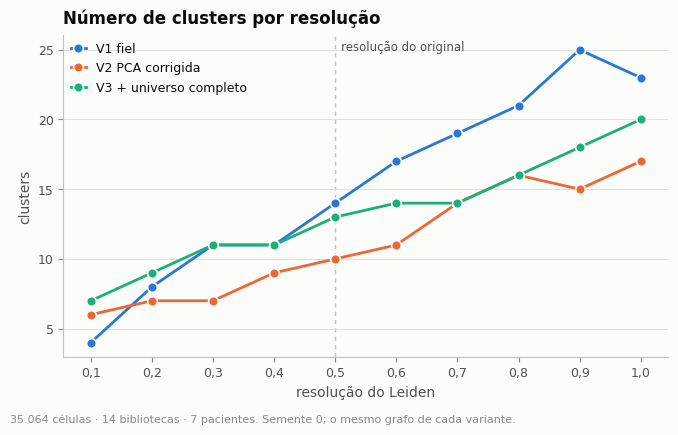

In [15]:
fig, ax = plt.subplots(figsize=(6.8, 4.2))
for v in VARS:
    ax.plot(RES, n_res[v].to_numpy(), "-o", color=VCOL[v], lw=2, ms=7, mec=INK["surface"], mew=1.2, label=VLAB[v])
ax.axvline(config.LEIDEN_RESOLUTION, color=INK["axis"], lw=1, ls=(0, (3, 3)), zorder=0)
ax.annotate("resolução do original", (config.LEIDEN_RESOLUTION, ax.get_ylim()[1]), xytext=(4, -4), textcoords="offset points",
            va="top", fontsize=8.5, color=INK["secondary"])
ax.set_xticks(RES)
plotting.decimals(ax, "x", 1)
ax.set_xlabel("resolução do Leiden")
ax.set_ylabel("clusters")
ax.set_title("Número de clusters por resolução")
ax.legend(loc="upper left")
plotting.note(fig, f"{F.n(N)} células · {plotting.N_DESIGN}. Semente 0; o mesmo grafo de cada variante.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "clusters_por_resolucao", description="Número de clusters por resolução do Leiden, por variante",
                 data=n_res_tab.reset_index(), data_index=False)
plt.show()

## 5. Algum cluster é técnico?

QC por cluster e destino das células sinalizadas nas etapas anteriores: baixo
conteúdo de RNA (A02), rótulo automático diferente de célula T (A02),
barcodes com sinal de célula B e conjugados T–B (A03), e as que o Scrublet
calibrado chamaria de doublet (A03). Um cluster é marcado como técnico quando
uma dessas categorias passa de 30% das suas células.

In [16]:
FLAGS = {"baixo_conteudo": "baixo conteúdo (< 1.000 UMIs)", "nao_T_azimuth": "rótulo automático não-T",
         "com_B": "sinal de célula B", "duplo_TB": "conjugado T–B", "scrublet_calibrado": "Scrublet calibrado",
         "intronica_alta": "fração intrônica alta"}
qc_por = {}
for v in VARS:
    g = obs.groupby(ckey(v), observed=True)
    t = pd.DataFrame({
        "celulas": g.size(),
        "umis_medianos": g["total_counts"].median(),
        "genes_medianos": g["n_genes_by_counts"].median(),
        "pct_mt_mediano": g["pct_counts_mt"].median(),
        "frac_intronica_mediana": flags.groupby(obs[ckey(v)], observed=True)["frac_intronica"].median(),
        "frac_ribo_mediana": flags.groupby(obs[ckey(v)], observed=True)["frac_ribo"].median(),
    })
    for k in FLAGS:
        t[k] = flags[k].astype(float).groupby(obs[ckey(v)], observed=True).mean()
    t["tecnico"] = (t[list(FLAGS)] > 0.30).any(axis=1)
    t["motivo"] = [", ".join(FLAGS[k] for k in FLAGS if r[k] > 0.30) for _, r in t.iterrows()]
    qc_por[v] = t
    io.save_table(t, NB, f"qc_por_cluster_{v}", description=f"QC e células sinalizadas por cluster ({v})")
glob = flags[list(FLAGS)].astype(float).mean()
destino = []
for v in VARS:
    for k, nome in FLAGS.items():
        m = flags[k].to_numpy(dtype=bool)
        if m.sum() == 0:
            continue
        vc = obs.loc[m, ckey(v)].value_counts()
        destino.append({"variante": v, "categoria": nome, "celulas": int(m.sum()), "cluster_principal": vc.index[0],
                        "frac_no_cluster_principal": float(vc.iloc[0] / m.sum()),
                        "frac_do_cluster_principal_que_e_da_categoria": float(qc_por[v].loc[vc.index[0], k])})
destino = pd.DataFrame(destino)
io.save_table(destino, NB, "destino_das_celulas_sinalizadas", index=False,
              description="Em que cluster se concentram as células sinalizadas em A02 e A03")
display(destino[destino["variante"] == BASE].drop(columns="variante").round(3))
qc_por[BASE].round(3)

,categoria,celulas,cluster_principal,frac_no_cluster_principal,frac_do_cluster_principal_que_e_da_categoria
12,baixo conteúdo (< 1.000 UMIs),730,3,0.551,0.083
13,rótulo automático não-T,1236,8,0.184,0.805
14,sinal de célula B,263,8,0.882,0.823
15,conjugado T–B,69,8,0.841,0.206
16,Scrublet calibrado,1760,0,0.337,0.074
17,fração intrônica alta,160,0,0.438,0.009


,celulas,umis_medianos,genes_medianos,pct_mt_mediano,frac_intronica_mediana,frac_ribo_mediana,baixo_conteudo,nao_T_azimuth,com_B,duplo_TB,scrublet_calibrado,intronica_alta,tecnico,motivo
leiden_V3,,,,,,,,,,,,,,
0,8067,12539.0,3712.0,3.082,0.339,0.240,0.000,0.025,0.000,0.000,0.074,0.009,False,
1,7575,9469.0,2840.0,3.299,0.214,0.351,0.025,0.003,0.000,0.000,0.062,0.002,False,
2,4997,8109.0,2454.0,3.974,0.150,0.366,0.018,0.029,0.000,0.000,0.062,0.000,False,
3,4841,6387.0,1749.0,2.857,0.071,0.460,0.083,0.018,0.000,0.000,0.012,0.000,False,
4,3751,13665.0,3889.0,2.534,0.360,0.249,0.000,0.002,0.000,0.000,0.019,0.010,False,
5,2012,8111.5,2832.5,2.949,0.257,0.245,0.003,0.017,0.000,0.000,0.049,0.009,False,
6,1851,7909.0,2269.0,2.691,0.111,0.363,0.012,0.032,0.000,0.000,0.024,0.000,False,
7,1186,8779.5,3264.5,3.457,0.384,0.153,0.012,0.140,0.000,0.000,0.073,0.003,False,
8,282,11144.0,3536.0,2.942,0.321,0.222,0.007,0.805,0.823,0.206,0.071,0.011,True,"rótulo automático não-T, sinal de célula B"


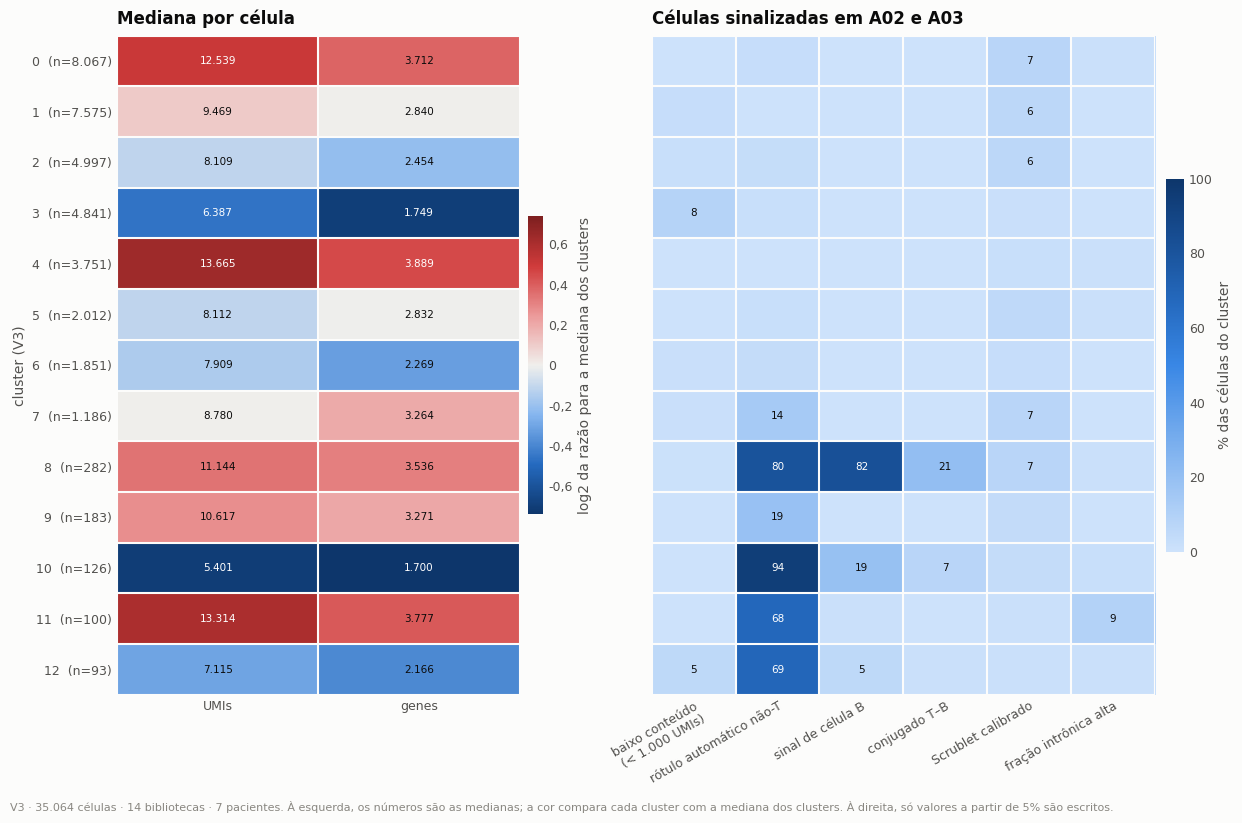

In [17]:
t = qc_por[BASE]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 0.42 * len(t) + 2.6), gridspec_kw={"width_ratios": [1, 1.25]})
m1 = pd.DataFrame({"UMIs": t["umis_medianos"], "genes": t["genes_medianos"]})
z = np.log2(m1 / m1.median())
z.index = [f"{c}  (n={F.n(n)})" for c, n in zip(t.index, t["celulas"])]
plotting.heatmap(a1, z, center=0, fmt=".1f", cbar_label="log2 da razão para a mediana dos clusters", xrotation=0)
for i, (_, r) in enumerate(m1.iterrows()):
    for j, val in enumerate(r):
        a1.texts[i * 2 + j].set_text(F.n(val))
a1.set_title("Mediana por célula")
a1.set_ylabel(f"cluster ({BASE})")
m2 = t[list(FLAGS)] * 100
m2.columns = [FLAGS[k].replace(" (", "\n(") for k in FLAGS]
m2.index = z.index
plotting.heatmap(a2, m2, vmin=0, vmax=100, fmt=".0f", annotate_above=5, cbar_label="% das células do cluster", xrotation=30)
a2.set_yticklabels([])
a2.set_title("Células sinalizadas em A02 e A03")
plotting.note(fig, f"{BASE} · {F.n(N)} células · {plotting.N_DESIGN}. À esquerda, os números são as medianas; a cor compara "
                   "cada cluster com a mediana dos clusters. À direita, só valores a partir de 5% são escritos.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "qc_por_cluster", description="QC e células sinalizadas por cluster (V3)",
                 data=t.rename_axis("cluster").reset_index(), data_index=False)
plt.show()

In [18]:
for v in VARS:
    tt = qc_por[v][qc_por[v]["tecnico"]]
    txt = "; ".join(f"cluster {c} ({F.n(r.celulas)} células: {r.motivo})" for c, r in tt.iterrows()) or "nenhum"
    print(f"{v}: clusters técnicos → {txt}")
print("taxa global de cada categoria:", "; ".join(f"{FLAGS[k]} {F.pct(x, 2)}" for k, x in glob.items()))

V1: clusters técnicos → cluster 11 (73 células: rótulo automático não-T, sinal de célula B); cluster 12 (66 células: rótulo automático não-T); cluster 13 (43 células: rótulo automático não-T, sinal de célula B)
V2: clusters técnicos → cluster 8 (294 células: rótulo automático não-T, sinal de célula B); cluster 9 (122 células: rótulo automático não-T)
V3: clusters técnicos → cluster 8 (282 células: rótulo automático não-T, sinal de célula B); cluster 10 (126 células: rótulo automático não-T); cluster 11 (100 células: rótulo automático não-T); cluster 12 (93 células: rótulo automático não-T)
taxa global de cada categoria: baixo conteúdo (< 1.000 UMIs) 2,08%; rótulo automático não-T 3,52%; sinal de célula B 0,75%; conjugado T–B 0,20%; Scrublet calibrado 5,02%; fração intrônica alta 0,46%


## 6. O ressequenciamento mudou os clusters?

A04 rodou as três variantes também sobre a corrida antiga. Nas células
presentes nas duas corridas, compara-se o agrupamento antigo com o novo, para
a mesma variante. A referência do que é "igual" é o ARI entre duas sementes
sobre o mesmo grafo (seção 4): duas execuções da mesma análise nos mesmos
dados já não coincidem exatamente.

In [19]:
par = obs[["cell_key"] + [ckey(v) for v in VARS]].merge(
    ant[["cell_key"] + [ckey(v) for v in VARS]], on="cell_key", suffixes=("_nova", "_antiga"))
linhas = []
for v in VARS:
    c = pl.clustering_agreement(par[f"{ckey(v)}_antiga"], par[f"{ckey(v)}_nova"])
    linhas.append({"variante": v, "células pareadas": len(par),
                   "clusters (antiga → nova)": f"{par[f'{ckey(v)}_antiga'].nunique()} → {par[f'{ckey(v)}_nova'].nunique()}",
                   "ARI antiga × nova": c["ARI"], "NMI antiga × nova": c["NMI"],
                   "células no cluster pareado": pl.matched_fraction(par[f"{ckey(v)}_antiga"], par[f"{ckey(v)}_nova"]),
                   "ARI de referência entre sementes": estab.loc[v, "ARI entre sementes (média)"]})
antnova = pd.DataFrame(linhas).set_index("variante")
io.save_table(antnova, NB, "antiga_vs_nova", description="Concordância do agrupamento entre a corrida antiga e o ressequenciamento")
print(f"células na corrida antiga: {F.n(len(ant))}; no ressequenciamento: {F.n(N)}; nas duas: {F.n(len(par))}")
antnova

células na corrida antiga: 34.931; no ressequenciamento: 35.064; nas duas: 34.796


,células pareadas,clusters (antiga → nova),ARI antiga × nova,NMI antiga × nova,células no cluster pareado,ARI de referência entre sementes
variante,,,,,,
V1,34796,14 → 14,0.438507,0.577367,0.621767,0.536263
V2,34796,12 → 10,0.494400,0.592663,0.656282,0.577769
V3,34796,11 → 13,0.523225,0.614671,0.754253,0.520447


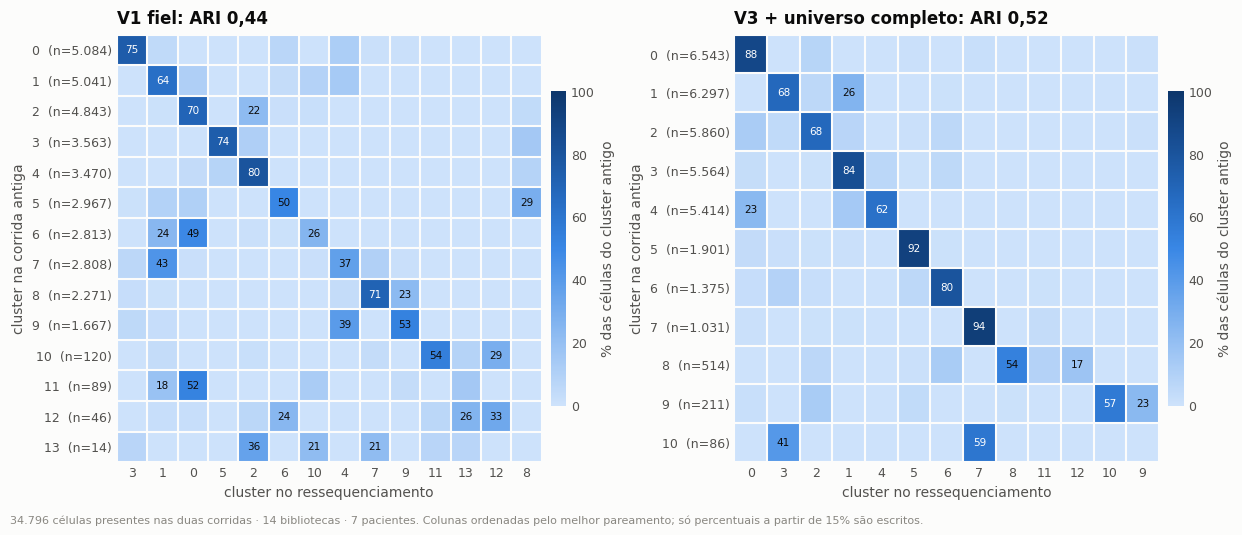

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
dados_fig = []
for ax, v in zip(axes, ["V1", BASE]):
    ct = pl.matched_contingency(par[f"{ckey(v)}_antiga"], par[f"{ckey(v)}_nova"])
    frac = ct.div(ct.sum(axis=1), axis=0) * 100
    frac.index = [f"{i}  (n={F.n(n)})" for i, n in zip(ct.index, ct.sum(axis=1))]
    plotting.heatmap(ax, frac, vmin=0, vmax=100, fmt=".0f", annotate_above=15,
                     cbar_label="% das células do cluster antigo", xrotation=0)
    ax.set_xlabel("cluster no ressequenciamento")
    ax.set_ylabel("cluster na corrida antiga")
    ax.set_title(f"{VLAB[v]}: ARI {F.f(antnova.loc[v, 'ARI antiga × nova'], 2)}")
    dados_fig.append(ct.stack().rename("celulas").reset_index().set_axis(["cluster_antiga", "cluster_nova", "celulas"], axis=1)
                     .assign(variante=v))
plotting.note(fig, f"{F.n(len(par))} células presentes nas duas corridas · {plotting.N_DESIGN}. Colunas ordenadas pelo melhor "
                   "pareamento; só percentuais a partir de 15% são escritos.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "antiga_vs_nova", description="Para onde vão as células de cada cluster antigo no ressequenciamento",
                 data=pd.concat(dados_fig), data_index=False)
plt.show()

## 7. Estimulado × não estimulado na composição dos clusters (V3)

Para cada cluster, a fração das células de cada biblioteca que cai nele,
pareada dentro do paciente. É o único contraste com réplica (n = 7 pacientes).
Duas ressalvas pesam na leitura. O teste exato de Wilcoxon com 7 pares não
pode dar p menor que 0,016, de modo que nenhum cluster sobrevive à correção
para o número de clusters testados. E a integração foi feita por biblioteca,
o que tende a aproximar justamente as duas bibliotecas de cada paciente.

In [21]:
sh = share_lib[BASE].reindex(clusters_of(BASE))
linhas = []
for c in sh.index:
    ns = pd.Series({p: sh.loc[c, f"{p}_NS"] for p in PATS})
    ml = pd.Series({p: sh.loc[c, f"{p}_ML"] for p in PATS})
    d = ml - ns
    pval = (float(stats.wilcoxon(ml, ns, zero_method="wilcox", alternative="two-sided", method="exact").pvalue)
            if (d != 0).all() else np.nan)
    linhas.append({"cluster": c, "mediana_NS": float(ns.median()), "mediana_ML": float(ml.median()),
                   "pacientes_ML_maior": int((d > 0).sum()), "diferenca_mediana": float(d.median()),
                   "p_wilcoxon_exato": pval,
                   "maior_diferenca_paciente": d.abs().idxmax(), "maior_diferenca": float(d[d.abs().idxmax()])})
estim = pd.DataFrame(linhas).set_index("cluster")
asc = estim["p_wilcoxon_exato"].dropna().sort_values()
bh = (asc * len(asc) / np.arange(1, len(asc) + 1))[::-1].cummin()[::-1].clip(upper=1)
estim["p_BH"] = bh.reindex(estim.index)
io.save_table(estim, NB, "estimulo_por_cluster", description="Fração de cada biblioteca por cluster, estimulado × não estimulado, pareado (n = 7)")
estim.round(4)

,mediana_NS,mediana_ML,pacientes_ML_maior,diferenca_mediana,p_wilcoxon_exato,maior_diferenca_paciente,maior_diferenca,p_BH
cluster,,,,,,,,
0,0.2979,0.1793,1,-0.1294,0.0312,CTH97,-0.2984,0.1250
1,0.2316,0.2076,4,0.0159,0.3750,CTH94,0.0457,0.5000
2,0.1184,0.1457,5,0.0282,0.4688,CTH97,-0.0645,0.5625
3,0.0978,0.1442,5,0.0278,0.2188,CTH97,0.2472,0.4375
4,0.1677,0.1120,1,-0.0551,0.0312,MB34,-0.0868,0.1250
5,0.0500,0.0587,6,0.0099,0.0469,PB20,0.0278,0.1406
6,0.0037,0.0497,7,0.0497,0.0156,CTH97,0.1680,0.1250
7,0.0397,0.0385,2,-0.0072,0.5781,HNP44,0.0175,0.6307
8,0.0020,0.0098,6,0.0061,0.2188,HNP44,0.0123,0.4375


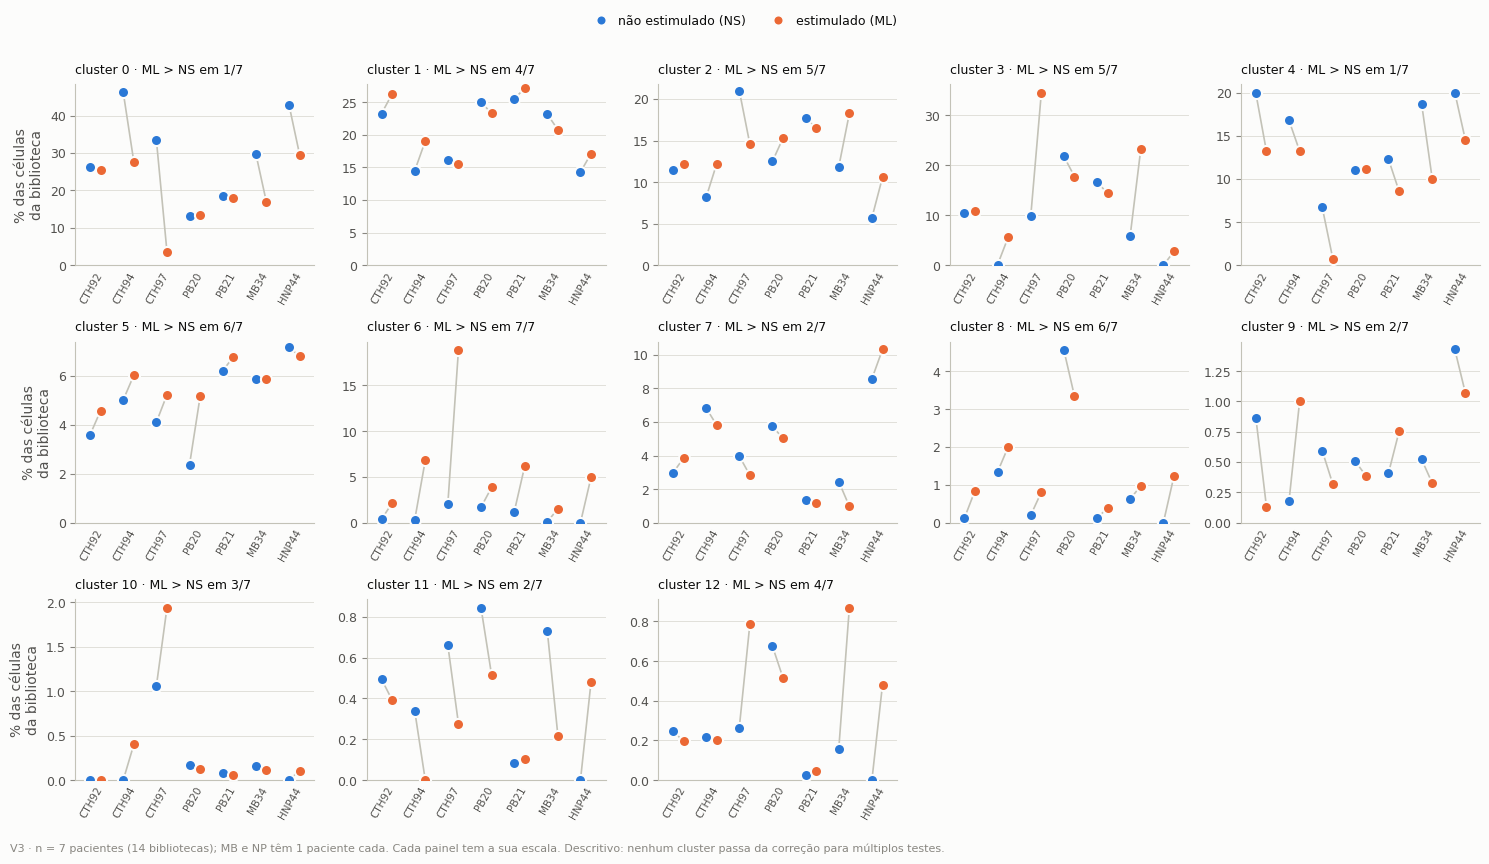

In [22]:
cl = clusters_of(BASE)
ncols = 5
nrows = int(np.ceil(len(cl) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.0 * ncols, 2.5 * nrows + 0.7), squeeze=False)
for k, c in enumerate(cl):
    ax = axes[k // ncols][k % ncols]
    plotting.paired_dots(ax, sh.loc[c] * 100)
    ax.set_xticklabels([p for p in PATS], rotation=60, ha="right", rotation_mode="anchor", fontsize=7.5)
    ax.set_title(f"cluster {c} · ML > NS em {estim.loc[c, 'pacientes_ML_maior']}/7", fontsize=9, fontweight="normal")
    ax.set_ylim(bottom=0)
    if k % ncols == 0:
        ax.set_ylabel("% das células\nda biblioteca")
for k in range(len(cl), nrows * ncols):
    axes[k // ncols][k % ncols].axis("off")
plotting.stim_legend(fig, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))
plotting.note(fig, f"{BASE} · n = {config.N_PATIENTS} pacientes ({config.N_LIBRARIES} bibliotecas); MB e NP têm 1 paciente cada. "
                   "Cada painel tem a sua escala. Descritivo: nenhum cluster passa da correção para múltiplos testes.", y=0.0)
fig.tight_layout(rect=(0, 0.01, 1, 0.97))
plotting.savefig(fig, NB, "estimulo_por_cluster", description="Fração de cada biblioteca em cada cluster, pareada por paciente (V3)",
                 data=(sh.T * 100).rename_axis("library_id").reset_index(), data_index=False)
plt.show()

## 8. Citocinas por cluster

As citocinas só existem no universo completo (V3): a interseção remove 12 das
16. A positividade é mostrada com três definições, da mais permissiva à mais
conservadora — pelo menos 1 UMI; pelo menos uma molécula sustentada por 3 ou
mais reads (C03: moléculas de 1–2 reads são as menos confiáveis); e pelo menos
2 UMIs (A02: em CTH97_ML o RNA ambiente explica boa parte dos eventos de 1 UMI).

In [23]:
CYT = [g for g in config.CYTOKINES if g in integ.var_names]
fora = [g for g in config.CYTOKINES if g not in integ.var_names]
C = pd.DataFrame(integ[:, CYT].layers["counts"].toarray(), index=obs["cell_key"].to_numpy(), columns=CYT).astype(int)

mp = io.load_data("C03_rarefacao_citocinas", "mol_painel")
mp = mp[mp["gene"].isin(CYT)].assign(cell_key=lambda d: d["library_id"] + "|" + d["barcode"])
mp = mp[mp["cell_key"].isin(C.index)]
umis_mol = mp.pivot_table(index="cell_key", columns="gene", values="umis", aggfunc="sum").reindex(index=C.index, columns=CYT).fillna(0).astype(int)
assert (umis_mol.to_numpy() == C.to_numpy()).all(), "contagens das citocinas diferem entre a matriz e molecule_info"
rmax = mp.pivot_table(index="cell_key", columns="gene", values="reads_max", aggfunc="max").reindex(index=C.index, columns=CYT).fillna(0)

pos = {"≥ 1 UMI": C >= 1, "molécula com ≥ 3 reads": rmax >= 3, "≥ 2 UMIs": C >= 2}
tot = pd.DataFrame({k: m.sum() for k, m in pos.items()})
tot["% das células (≥ 1 UMI)"] = tot["≥ 1 UMI"] / N * 100
tot["na interseção (V1, V2)"] = integ.var.loc[CYT, "na_intersecao"].to_numpy()
tot["células de CTH97_ML entre as positivas"] = [(pos["≥ 1 UMI"][g].to_numpy() & (lib_arr == "CTH97_ML")).sum() / max(pos["≥ 1 UMI"][g].sum(), 1)
                                                   for g in CYT]
io.save_table(tot, NB, "citocinas_positivas", description="Células positivas por citocina sob três definições de positividade")
print(f"citocinas fora do objeto (menos de {config.GLOBAL_MIN_CELLS} células no conjunto): {', '.join(fora) or 'nenhuma'}")
print("contagens das citocinas conferidas contra molecule_info: idênticas")
tot.round(3)

citocinas fora do objeto (menos de 3 células no conjunto): IL3
contagens das citocinas conferidas contra molecule_info: idênticas


,≥ 1 UMI,molécula com ≥ 3 reads,≥ 2 UMIs,% das células (≥ 1 UMI),"na interseção (V1, V2)",células de CTH97_ML entre as positivas
IFNG,1098,956,436,3.131,True,0.572
TNF,2319,2000,580,6.614,True,0.141
IL2,95,78,20,0.271,False,0.021
IL4,104,93,10,0.297,False,0.106
IL5,307,263,34,0.876,True,0.007
IL9,143,115,69,0.408,False,0.965
IL10,58,48,10,0.165,False,0.034
IL13,68,55,20,0.194,False,0.294
IL17A,81,75,56,0.231,False,0.827
IL17F,315,212,89,0.898,False,0.911


In [24]:
cl_arr = obs[ckey(BASE)].astype(str).to_numpy()
por_cluster = {k: m.groupby(cl_arr).mean().reindex(clusters_of(BASE)) * 100 for k, m in pos.items()}
n_por_cluster = pos["≥ 1 UMI"].groupby(cl_arr).sum().reindex(clusters_of(BASE))
conc = pd.DataFrame({
    "células positivas": pos["≥ 1 UMI"].sum(),
    "cluster com mais positivas": n_por_cluster.idxmax(),
    "fração das positivas nesse cluster": n_por_cluster.max() / pos["≥ 1 UMI"].sum(),
    "% do cluster positivo": [por_cluster["≥ 1 UMI"].loc[n_por_cluster[g].idxmax(), g] for g in CYT],
})
conc["CTH97_ML nesse cluster"] = [comp[BASE].loc[c, "CTH97_ML"] / comp[BASE].loc[c].sum() for c in conc["cluster com mais positivas"]]
io.save_table(por_cluster["≥ 1 UMI"], NB, "citocinas_por_cluster_1umi", description="% de células positivas (≥ 1 UMI) por cluster da V3")
io.save_table(por_cluster["≥ 2 UMIs"], NB, "citocinas_por_cluster_2umis", description="% de células positivas (≥ 2 UMIs) por cluster da V3")
io.save_table(conc, NB, "citocinas_concentracao", description="Em que cluster se concentram as células positivas de cada citocina")
conc.round(3)

,células positivas,cluster com mais positivas,fração das positivas nesse cluster,% do cluster positivo,CTH97_ML nesse cluster
IFNG,1098,6,0.265,15.721,0.478
TNF,2319,0,0.349,10.029,0.021
IL2,95,0,0.389,0.459,0.021
IL4,104,0,0.337,0.434,0.021
IL5,307,0,0.423,1.612,0.021
IL9,143,6,0.483,3.728,0.478
IL10,58,0,0.379,0.273,0.021
IL13,68,6,0.250,0.918,0.478
IL17A,81,6,0.630,2.755,0.478
IL17F,315,6,0.365,6.213,0.478


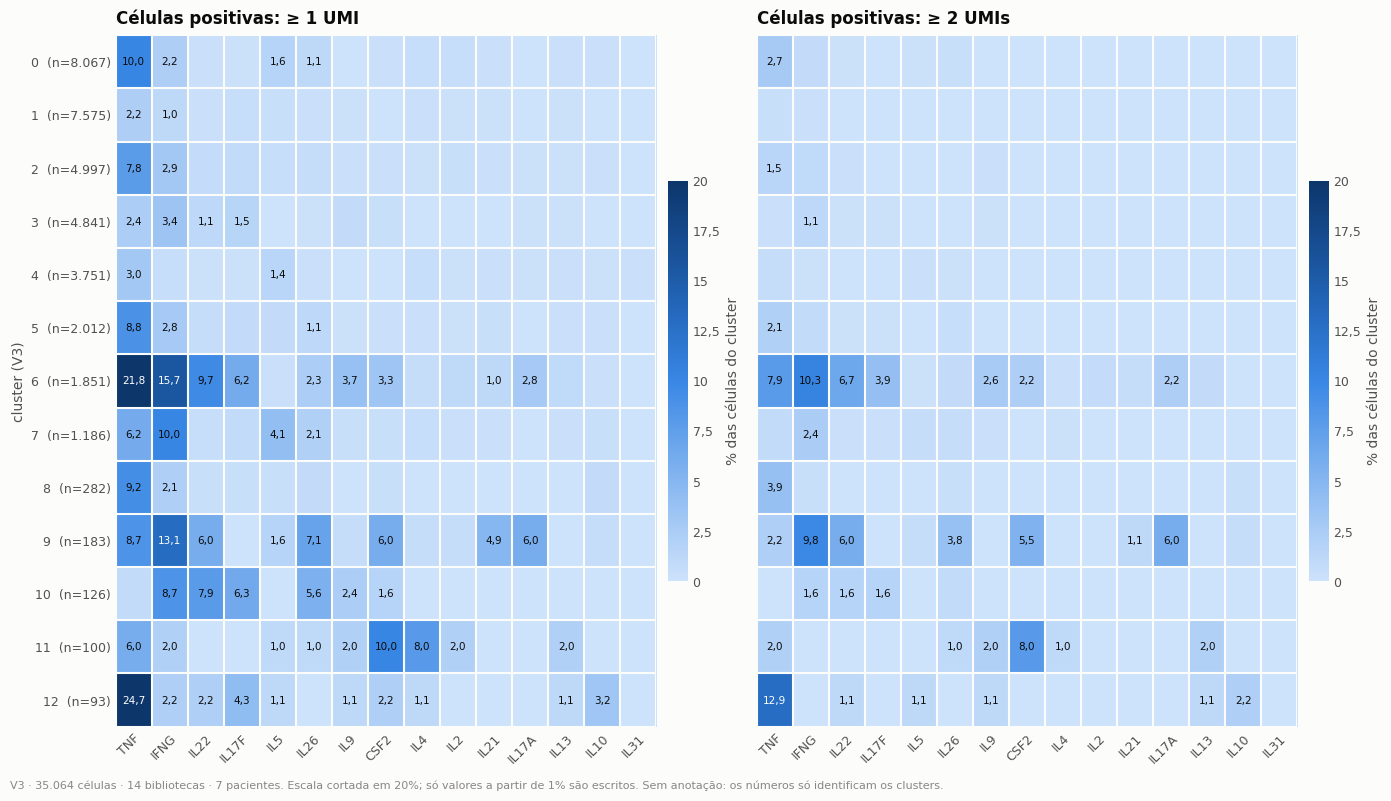

In [25]:
ordem_g = tot["≥ 1 UMI"].sort_values(ascending=False).index.tolist()
tam_b = obs[ckey(BASE)].value_counts().reindex(clusters_of(BASE))
fig, axes = plt.subplots(1, 2, figsize=(14, 0.42 * len(tam_b) + 2.4), sharey=True)
for ax, k in zip(axes, ["≥ 1 UMI", "≥ 2 UMIs"]):
    m = por_cluster[k][ordem_g].copy()
    m.index = [f"{c}  (n={F.n(tam_b[c])})" for c in m.index]
    plotting.heatmap(ax, m, vmin=0, vmax=20, fmt=".1f", annotate_above=1.0, cbar_label="% das células do cluster")
    ax.set_title(f"Células positivas: {k}")
axes[0].set_ylabel(f"cluster ({BASE})")
plotting.note(fig, f"{BASE} · {F.n(N)} células · {plotting.N_DESIGN}. Escala cortada em 20%; só valores a partir de 1% são escritos. "
                   "Sem anotação: os números só identificam os clusters.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "citocinas_por_cluster", description="% de células positivas para cada citocina, por cluster da V3",
                 data=por_cluster["≥ 1 UMI"].rename_axis("cluster").reset_index(), data_index=False)
plt.show()

## 9. Os problemas anteriores se repetem?

In [26]:
tab_dir = config.TABLES
etapas = pd.read_csv(tab_dir / "A01_preprocessamento" / "celulas_por_etapa.csv", index_col=0)
scr = pd.read_csv(tab_dir / "A01_preprocessamento" / "scrublet_original.csv", index_col=0)
cit = pd.read_csv(tab_dir / "C02_antigo_vs_novo" / "citocinas_antigo_novo.csv", index_col=0)
ganho = pd.read_csv(tab_dir / "C02_antigo_vs_novo" / "ganho_por_biblioteca.csv", index_col=0)
var4 = pd.read_csv(tab_dir / "A04_processamento_integracao" / "variantes.csv", index_col=0)
acordo4 = pd.read_csv(tab_dir / "A04_processamento_integracao" / "concordancia_entre_variantes.csv", index_col=0)
etapas = etapas.reindex(LIBS)
cel_ant, cel_nova = int(etapas["cellranger_antiga"].sum()), int(etapas["cellranger_nova"].sum())
fin_ant, fin_nova = int(etapas["scrublet_antiga"].sum()), int(etapas["scrublet_nova"].sum())
scr_rem, scr_ent, scr_esp = int(scr["doublets_chamados"].sum()), int(scr["entrada"].sum()), float(scr["doublets_esperados_10x"].sum())
n_fora = int((~integ.var.loc[CYT, "na_intersecao"]).sum()) + len(fora)
cit_c = cit[cit["classe"] == "citocina"]
linhas_cit = "; ".join(f"{g} {F.pct(r.pct_antiga, 2)} → {F.pct(r.pct_nova, 2)}" for g, r in cit_c.loc[["IFNG", "IL4", "IL10", "IL17A"]].iterrows())
tecnicos = qc_por[BASE][qc_por[BASE]["tecnico"]]

vered = pd.DataFrame([
    ["baixa detecção de citocinas", "motivo do ressequenciamento",
     f"células positivas, antiga → nova: {linhas_cit}; ganho mediano de UMIs por célula de "
     f"{F.pct(ganho['razao_umis'].median() - 1, 0, signed=True)} (C02, C03)",
     "repete", "a profundidade não é o limite; mais sequenciamento não resolve"],
    ["citocinas removidas pela interseção entre bibliotecas", "IL4, IL9, IL10, IL13, IL17A, IL17F, IL21 fora do objeto",
     f"{n_fora} das {len(config.CYTOKINES)} citocinas ficam fora da interseção (V1, V2); na V3 só {len(fora)} "
     f"({', '.join(fora) or '—'})", "repete na V1 · resolvido na V3", "união + filtro global no lugar da interseção"],
    ["PCA sobre contagens cruas", "50 componentes com 98,2% da variância; eixos seguindo o nº de UMIs",
     f"V1: {F.pct(var4.loc[VLAB['V1'], 'variância nas 50 componentes'])} da variância em 50 componentes; variância do nº de UMIs "
     f"explicada pelo cluster {F.f(med['nova · V1'], 2)} (V1) contra {F.f(med['nova · V3'], 2)} (V3)",
     "repete na V1 · resolvido na V2/V3", "PCA sobre lognorm escalonada"],
    ["clusters dependentes do defeito da PCA", f"ARI original × corrigido de {F.f(acordo4.loc['corrida antiga: original × PCA corrigida', 'ARI'], 2)}",
     f"ARI V1 × V2 de {F.f(acordo4.loc['V1 × V2', 'ARI'], 2)}", "repete", "não anotar os clusters da V1"],
    ["Scrublet quase não remove doublets", "38 de 34.969 células (0,11%)",
     f"{F.n(scr_rem)} de {F.n(scr_ent)} ({F.pct(scr_rem / scr_ent, 2)}), contra ~{F.n(scr_esp)} esperados pela taxa do 10x (A01, A03)",
     "repete", "threshold calibrado pela taxa esperada, por biblioteca; não há excesso de doublets (A03)"],
    ["baixa recuperação e desbalanço entre bibliotecas", "37.161 células; HNP44_NS com 76 após o QC",
     f"{F.n(cel_nova)} células chamadas ({F.n(fin_nova)} após o QC); de {F.n(n_lib.min())} ({n_lib.idxmin()}) a "
     f"{F.n(n_lib.max())} ({n_lib.idxmax()}); {F.pct(n_pat.max() / N, 0)} de {n_pat.idxmax()}",
     "repete", "ressequenciar não cria células; a limitação é do carregamento"],
    ["o agrupamento muda com o ressequenciamento?", "—",
     f"{BASE}: ARI antiga × nova {F.f(antnova.loc[BASE, 'ARI antiga × nova'], 2)} (referência entre sementes "
     f"{F.f(antnova.loc[BASE, 'ARI de referência entre sementes'], 2)}); {F.pct(antnova.loc[BASE, 'células no cluster pareado'], 0)} "
     f"das células no cluster pareado", "—", "os dados novos podem substituir os antigos sem mudar a estrutura"],
    ["clusters técnicos", "29 células B no objeto de células T",
     (f"{BASE}: " + "; ".join(f"cluster {c} ({F.n(r.celulas)} células: {r.motivo})" for c, r in tecnicos.iterrows()))
     if len(tecnicos) else f"{BASE}: nenhum cluster com mais de 30% de células sinalizadas",
     "—", "remover os clusters técnicos antes de anotar" if len(tecnicos) else "nenhuma remoção por cluster necessária"],
], columns=["problema", "na corrida antiga", "no ressequenciamento", "veredito", "o que fazer"]).set_index("problema")
io.save_table(vered, NB, "problemas_anteriores", description="Os problemas da análise anterior se repetem no ressequenciamento?")
with pd.option_context("display.max_colwidth", None):
    display(vered)

,na corrida antiga,no ressequenciamento,veredito,o que fazer
problema,,,,
baixa detecção de citocinas,motivo do ressequenciamento,"células positivas, antiga → nova: IFNG 2,63% → 3,02%; IL4 0,22% → 0,28%; IL10 0,13% → 0,16%; IL17A 0,20% → 0,22%; ganho mediano de UMIs por célula de +8% (C02, C03)",repete,a profundidade não é o limite; mais sequenciamento não resolve
citocinas removidas pela interseção entre bibliotecas,"IL4, IL9, IL10, IL13, IL17A, IL17F, IL21 fora do objeto","12 das 16 citocinas ficam fora da interseção (V1, V2); na V3 só 1 (IL3)",repete na V1 · resolvido na V3,união + filtro global no lugar da interseção
PCA sobre contagens cruas,"50 componentes com 98,2% da variância; eixos seguindo o nº de UMIs","V1: 98,1% da variância em 50 componentes; variância do nº de UMIs explicada pelo cluster 0,57 (V1) contra 0,22 (V3)",repete na V1 · resolvido na V2/V3,PCA sobre lognorm escalonada
clusters dependentes do defeito da PCA,"ARI original × corrigido de 0,09","ARI V1 × V2 de 0,08",repete,não anotar os clusters da V1
Scrublet quase não remove doublets,"38 de 34.969 células (0,11%)","62 de 35.126 (0,18%), contra ~1.554 esperados pela taxa do 10x (A01, A03)",repete,"threshold calibrado pela taxa esperada, por biblioteca; não há excesso de doublets (A03)"
baixa recuperação e desbalanço entre bibliotecas,37.161 células; HNP44_NS com 76 após o QC,37.898 células chamadas (35.064 após o QC); de 70 (HNP44_NS) a 10.629 (PB21_ML); 41% de PB21,repete,ressequenciar não cria células; a limitação é do carregamento
o agrupamento muda com o ressequenciamento?,—,"V3: ARI antiga × nova 0,52 (referência entre sementes 0,52); 75% das células no cluster pareado",—,os dados novos podem substituir os antigos sem mudar a estrutura
clusters técnicos,29 células B no objeto de células T,"V3: cluster 8 (282 células: rótulo automático não-T, sinal de célula B); cluster 10 (126 células: rótulo automático não-T); cluster 11 (100 células: rótulo automático não-T); cluster 12 (93 células: rótulo automático não-T)",—,remover os clusters técnicos antes de anotar


## Problemas encontrados

In [27]:
b = compos[compos["variante"] == BASE]
um_b = b[b["de_um_paciente"]]
if len(um_b):
    log.add("MAJOR", f"clusters da {BASE}", "há clusters formados por células de um único paciente",
            evidence="; ".join(f"cluster {r.cluster}: {F.n(r.celulas)} células, {F.pct(r.frac_do_cluster_no_paciente, 0)} de "
                               f"{r.paciente_dominante} (biblioteca {r.biblioteca_dominante})" for r in um_b.itertuples()),
            impact="um cluster de um paciente não permite separar estado celular de efeito do doador ou do preparo; "
                   "qualquer comparação entre grupos nesses clusters tem n = 1",
            recommendation="tratar esses clusters como específicos de amostra na anotação e não usá-los em contrastes entre grupos")
log.add("MINOR" if estab.loc[BASE, "ARI entre sementes (mínimo)"] >= 0.7 else "MAJOR", f"estabilidade do Leiden ({BASE})",
        "o número de clusters cresce com a resolução sem patamar claro",
        evidence=f"{estab.loc[BASE, 'clusters de 0,1 a 1,0']} clusters de 0,1 a 1,0; ARI entre sementes na resolução 0,5: média "
                 f"{F.f(estab.loc[BASE, 'ARI entre sementes (média)'], 2)}, mínimo {F.f(estab.loc[BASE, 'ARI entre sementes (mínimo)'], 2)}; "
                 f"clusters por semente: {estab.loc[BASE, 'clusters por semente']}",
        impact="a resolução 0,5 é uma convenção herdada do original, não uma escala indicada pelos dados",
        recommendation="escolher a resolução na anotação, por marcadores, e conferir a estabilidade dos clusters que forem interpretados")
if len(tecnicos):
    log.add("MINOR", f"clusters técnicos ({BASE})", "há clusters formados por células sinalizadas no pré-processamento",
            evidence="; ".join(f"cluster {c}: {F.n(r.celulas)} células ({r.motivo})" for c, r in tecnicos.iterrows()),
            impact="esses clusters não são estados de células T CD4",
            recommendation="remover antes da anotação")
log.add("INFO", "ressequenciamento × agrupamento", "[VERIFICAÇÃO] o agrupamento da corrida antiga se mantém nos dados novos",
        evidence=f"{BASE}: ARI antiga × nova {F.f(antnova.loc[BASE, 'ARI antiga × nova'], 2)}, referência entre sementes "
                 f"{F.f(antnova.loc[BASE, 'ARI de referência entre sementes'], 2)}; {F.n(len(par))} células pareadas",
        impact="o ressequenciamento não altera a estrutura do dado; as conclusões sobre o processamento valem para as duas corridas",
        recommendation="nenhuma")
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    0
MAJOR       2
MINOR       1
INFO        1


severity,location,problem,evidence,impact,recommendation
MAJOR,clusters da V3,há clusters formados por células de um único paciente,"cluster 10: 126 células, 85% de CTH97 (biblioteca CTH97_ML)",um cluster de um paciente não permite separar estado celular de efeito do doador ou do preparo; qualquer comparação entre grupos nesses clusters tem n = 1,tratar esses clusters como específicos de amostra na anotação e não usá-los em contrastes entre grupos
MAJOR,estabilidade do Leiden (V3),o número de clusters cresce com a resolução sem patamar claro,"7 → 20 clusters de 0,1 a 1,0; ARI entre sementes na resolução 0,5: média 0,52, mínimo 0,44; clusters por semente: 13 / 14 / 13 / 13","a resolução 0,5 é uma convenção herdada do original, não uma escala indicada pelos dados","escolher a resolução na anotação, por marcadores, e conferir a estabilidade dos clusters que forem interpretados"
MINOR,clusters técnicos (V3),há clusters formados por células sinalizadas no pré-processamento,"cluster 8: 282 células (rótulo automático não-T, sinal de célula B); cluster 10: 126 células (rótulo automático não-T); cluster 11: 100 células (rótulo automático não-T); cluster 12: 93 células (rótulo automático não-T)",esses clusters não são estados de células T CD4,remover antes da anotação
INFO,ressequenciamento × agrupamento,[VERIFICAÇÃO] o agrupamento da corrida antiga se mantém nos dados novos,"V3: ARI antiga × nova 0,52, referência entre sementes 0,52; 34.796 células pareadas",o ressequenciamento não altera a estrutura do dado; as conclusões sobre o processamento valem para as duas corridas,nenhuma


## Conclusão

**A estrutura é compartilhada entre pacientes.** Na V3, os 9 maiores clusters
reúnem células de todos os pacientes (número efetivo de 3,3 a 6,8 de 7;
mediana 5,6). O único cluster de um paciente só (10, 126 células, 85% de
CTH97) é formado por células que o rótulo automático não classifica como T.

**Quatro clusters pequenos são técnicos.** O 8 (282 células) reúne células B
e conjugados T–B; o 10, o 11 e o 12 (126, 100 e 93 células) são de não-T.
Somam 601 células (1,7%) e devem sair antes da anotação. As células de baixo
conteúdo não formam cluster próprio (55% caem no cluster 3, onde são 8%), e as
que o Scrublet calibrado marcaria se espalham (no máximo 7% de um cluster):
não há cluster de doublets.

**A integração funciona, com uma exceção.** Os vizinhos da mesma biblioteca
caem de 50% para 10% (mediana) com o Harmony. CTH97_ML continua com 48% de
vizinhos próprios contra 13% esperados: ocupa uma região só sua (clusters 3
e 6), coerente com o perfil atípico visto em A02.

**O defeito de profundidade se repete na V1 e some na V2/V3.** Dentro de cada
biblioteca, o cluster explica 57% da variância do log do número de UMIs na
V1 — o mesmo valor da corrida antiga — contra 19–22% na V2 e na V3.

**As fronteiras da massa central são instáveis.** Entre sementes do Leiden, o
ARI da V3 fica em 0,52 e o número de clusters varia de 13 a 14; de 0,1 a 1,0
de resolução o número de clusters vai de 7 a 20 sem patamar. Seis clusters
reaparecem quase iguais em qualquer semente (Jaccard ≥ 0,75: 5, 7, 8, 9, 10 e
12); o cluster 2 é um recorte arbitrário (0,41) e os grandes ficam entre 0,53
e 0,71. A resolução 0,5 é uma convenção herdada, não uma escala dos dados.

**O ressequenciamento não muda o agrupamento.** Na V3, o ARI entre a corrida
antiga e a nova (0,52) é igual ao ARI entre duas sementes da mesma análise
(0,52), com 75% das células no cluster pareado.

**Estímulo e citocinas, descritivo.** O cluster 6 tem mais células nas
bibliotecas estimuladas nos 7 pacientes (p exato 0,016; 0,13 após correção
para 13 clusters) e concentra as células positivas para IFNG (16% do
cluster), TNF, IL22 e IL17F; 48% das suas células vêm de CTH97_ML. Com a
definição conservadora (≥ 2 UMIs) as positivas caem muito — IFNG de 1.098
para 436, IL4 de 104 para 10, IL10 de 58 para 10. Fica como hipótese para a
etapa de anotação, não como resultado.

In [28]:
feitos = io.manifest()
feitos = feitos[feitos["stage"] == NB][["name", "kind"]].drop_duplicates(keep="last")
print(f"{len(feitos)} artefatos gravados por este notebook:")
print(feitos.to_string(index=False))

45 artefatos gravados por este notebook:
                             name   kind
                    composicao_V1  table
                    composicao_V2  table
                    composicao_V3  table
              clusters_composicao  table
          clusters_de_um_paciente  table
    fig_composicao_por_biblioteca figure
    fig_composicao_por_biblioteca  table
          fig_umap_por_biblioteca figure
          fig_umap_por_biblioteca  table
             fig_umap_por_cluster figure
             fig_umap_por_cluster  table
                   mistura_resumo  table
           mistura_por_biblioteca  table
separacao_estimulo_por_biblioteca  table
       fig_mistura_de_bibliotecas figure
       fig_mistura_de_bibliotecas  table
 profundidade_eta2_por_biblioteca  table
                profundidade_eta2  table
      fig_profundidade_e_clusters figure
      fig_profundidade_e_clusters  table
                     estabilidade  table
           clusters_por_resolucao  table
         estabil